In [1]:
%matplotlib inline

import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.datasets import fetch_openml, make_moons
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    log_loss,
)
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42
np.set_printoptions(precision=4, suppress=True)
plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
# The first run downloads MNIST. Later runs use scikit-learn's cache.
try:
    mnist = fetch_openml("mnist_784", version=1, as_frame=False, parser="auto")
except TypeError:  # Compatibility with older scikit-learn versions
    mnist = fetch_openml("mnist_784", version=1, as_frame=False)

X_raw = mnist.data
y_raw = mnist.target.astype(np.int64)

print("Complete input shape:", X_raw.shape)
print("Target shape:", y_raw.shape)
print("Raw pixel range:", X_raw.min(), "to", X_raw.max())

Complete input shape: (70000, 784)
Target shape: (70000,)
Raw pixel range: 0 to 255


In [4]:
all_indices = np.arange(len(y_raw))
development_indices, test_indices = train_test_split(all_indices, test_size=10000, stratify=y_raw, random_state=SEED)

comparison_train_indices, comparison_valid_indices = train_test_split(development_indices, train_size=12000, test_size=3000, stratify=y_raw[development_indices], random_state=SEED)

X_compare_train = X_raw[comparison_train_indices].astype(np.float32) / 255.0
X_compare_valid = X_raw[comparison_valid_indices].astype(np.float32) / 255.0
y_compare_train = y_raw[comparison_train_indices]
y_compare_valid = y_raw[comparison_valid_indices]

print("Architecture-training subset:", X_compare_train.shape)
print("Architecture-validation subset:", X_compare_valid.shape)
print("Reserved full development set:", len(development_indices))
print("Untouched test set:", len(test_indices))

Architecture-training subset: (12000, 784)
Architecture-validation subset: (3000, 784)
Reserved full development set: 60000
Untouched test set: 10000


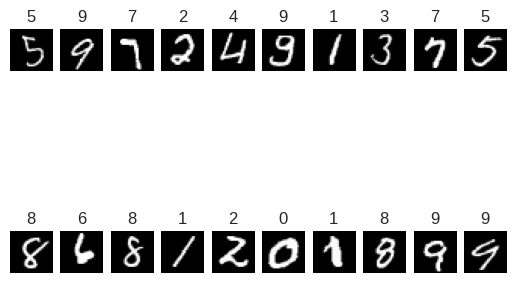

In [5]:
fig, axes = plt.subplots(2, 10)
for ax, image, label in zip(axes.ravel(), X_compare_train[:20], y_compare_train[:20]):
    ax.imshow(image.reshape(28, 28), cmap='gray')
    ax.set_title(str(label))
    ax.axis("off")
plt.show()

In [10]:
architectures = {
    "arch_1": (256, 128, 64),
    "arch_2": (1024, 1024, 1024),
    "arch_3": (128, 64),
    "arch_4": (128,),
}

In [11]:
def count_parameters(layer_sizes):
    return sum(n_in * n_out + n_out for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:]))

In [12]:
# count_parameters((784, *architectures["arch_1"], 10))
count_parameters((784, *architectures["arch_4"], 10))

101770

In [13]:
(784 * 128) + 128 + (128 * 10) + 10

101770

In [16]:
layer_sizes = (784, *architectures["arch_4"], 10)
for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:]):
    print(n_in, n_out)

784 128
128 10


In [18]:
layer_sizes[:-1], layer_sizes[1:]

((784, 128), (128, 10))

In [21]:
for name, hidden_layers in architectures.items():
    layer_sizes = (784, *hidden_layers, 10)
    print(f"name:{name}, {str(layer_sizes)}, {count_parameters(layer_sizes)}")

name:arch_1, (784, 256, 128, 64, 10), 242762
name:arch_2, (784, 1024, 1024, 1024, 10), 2913290
name:arch_3, (784, 128, 64, 10), 109386
name:arch_4, (784, 128, 10), 101770


In [23]:
COMPARISON_EPOCHS = 20

def train_architecture(name, hidden_layers):
    model = MLPClassifier(
        hidden_layer_sizes=hidden_layers,
        activation="relu",
        solver="adam",
        learning_rate_init=0.001,
        batch_size=128,
        alpha=1e-4,
        max_iter=COMPARISON_EPOCHS,
        random_state=SEED,
    )

    start = time.perf_counter()
    model.fit(X_compare_train, y_compare_train)
    elapsed = time.perf_counter() - start

    train_prediction = model.predict(X_compare_train)
    valid_prediction = model.predict(X_compare_valid)
    valid_probability = model.predict_proba(X_compare_valid)

    result = {
        "name": name,
        "architecture": str(hidden_layers),
        "parameters": count_parameters((784, *hidden_layers, 10)),
        "epochs": model.n_iter_,
        "training_seconds": elapsed,
        "train_accuracy": accuracy_score(y_compare_train, train_prediction),
        "validation_accuracy": accuracy_score(y_compare_valid, valid_prediction),
        "validation_loss": log_loss(
            y_compare_valid,
            valid_probability,
            labels=model.classes_,
        ),
    }
    return model, result


In [24]:
candidate_models = {}
experiment_rows = []

for name, hidden_layers in architectures.items():
    print(f"Training {name}: {hidden_layers}")
    model, result = train_architecture(name, hidden_layers)
    candidate_models[name] = model
    experiment_rows.append(result)

architecture_results = pd.DataFrame(experiment_rows).sort_values(
    ["validation_accuracy", "parameters"],
    ascending=[False, True],
).reset_index(drop=True)

architecture_results.round(4)

Training arch_1: (256, 128, 64)
Training arch_2: (1024, 1024, 1024)
Training arch_3: (128, 64)
Training arch_4: (128,)


,name,architecture,parameters,epochs,training_seconds,train_accuracy,validation_accuracy,validation_loss
0,arch_2,"(1024, 1024, 1024)",2913290,20,259.3562,0.9975,0.9673,0.1618
1,arch_1,"(256, 128, 64)",242762,20,28.0578,1.0000,0.9610,0.1882
2,arch_3,"(128, 64)",109386,20,9.0180,1.0000,0.9563,0.1914
3,arch_4,"(128,)",101770,20,11.1225,0.9982,0.9470,0.1862


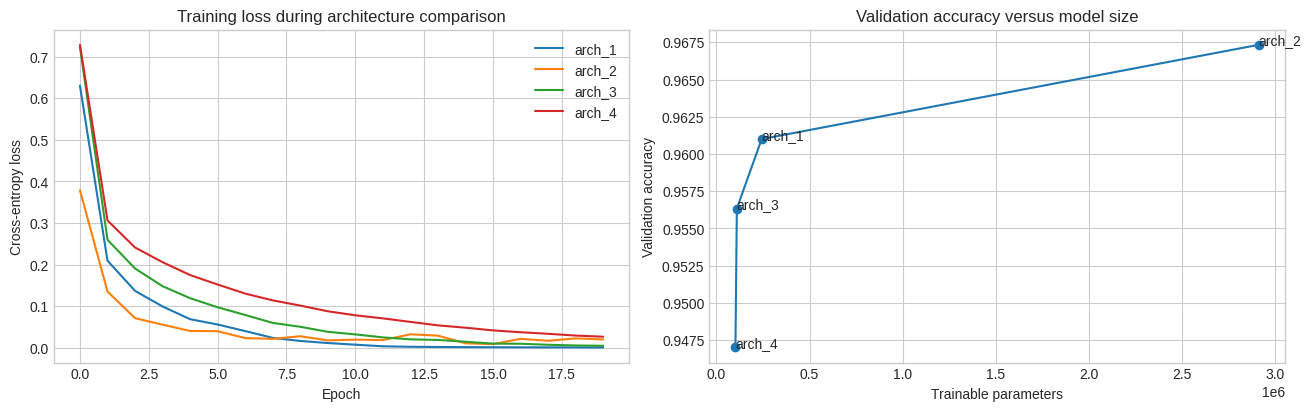

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)

for name, model in candidate_models.items():
    axes[0].plot(model.loss_curve_, label=name)
axes[0].set_title("Training loss during architecture comparison")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()

ordered = architecture_results.sort_values("parameters")
axes[1].plot(
    ordered["parameters"],
    ordered["validation_accuracy"],
    marker="o",
)
for _, row in ordered.iterrows():
    axes[1].annotate(
        row["name"],
        (row["parameters"], row["validation_accuracy"]),
    )
axes[1].set_title("Validation accuracy versus model size")
axes[1].set_xlabel("Trainable parameters")
axes[1].set_ylabel("Validation accuracy")

plt.show()

In [26]:
selected_architecture = architectures["arch_1"]

X_full_train = X_raw[development_indices].astype(np.float32) / 255.0
y_full_train = y_raw[development_indices]
X_test = X_raw[test_indices].astype(np.float32) / 255.0
y_test = y_raw[test_indices]

FULL_TRAIN_EPOCHS = 25

final_model = MLPClassifier(
    hidden_layer_sizes=selected_architecture,
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    batch_size=128,
    alpha=1e-4,
    max_iter=FULL_TRAIN_EPOCHS,
    random_state=SEED,
)

start = time.perf_counter()
final_model.fit(X_full_train, y_full_train)
full_training_seconds = time.perf_counter() - start

print("Training examples:", len(X_full_train))
print("Epochs used:", final_model.n_iter_)
print("Training time:", round(full_training_seconds, 1), "seconds")

Training examples: 60000
Epochs used: 25
Training time: 179.1 seconds


In [27]:
test_probability = final_model.predict_proba(X_test)
test_prediction = final_model.predict(X_test)

test_accuracy = accuracy_score(y_test, test_prediction)
test_loss = log_loss(y_test, test_probability, labels=final_model.classes_)

print("Test accuracy:", round(test_accuracy, 4))
print("Test cross-entropy:", round(test_loss, 4))
print()
print(classification_report(y_test, test_prediction, digits=3))

Test accuracy: 0.9816
Test cross-entropy: 0.0972

              precision    recall  f1-score   support

           0      0.988     0.993     0.990       986
           1      0.989     0.992     0.991      1125
           2      0.993     0.981     0.987       999
           3      0.988     0.966     0.977      1020
           4      0.976     0.982     0.979       975
           5      0.972     0.987     0.979       902
           6      0.990     0.993     0.991       982
           7      0.976     0.982     0.979      1042
           8      0.963     0.984     0.973       975
           9      0.980     0.958     0.969       994

    accuracy                          0.982     10000
   macro avg      0.981     0.982     0.981     10000
weighted avg      0.982     0.982     0.982     10000



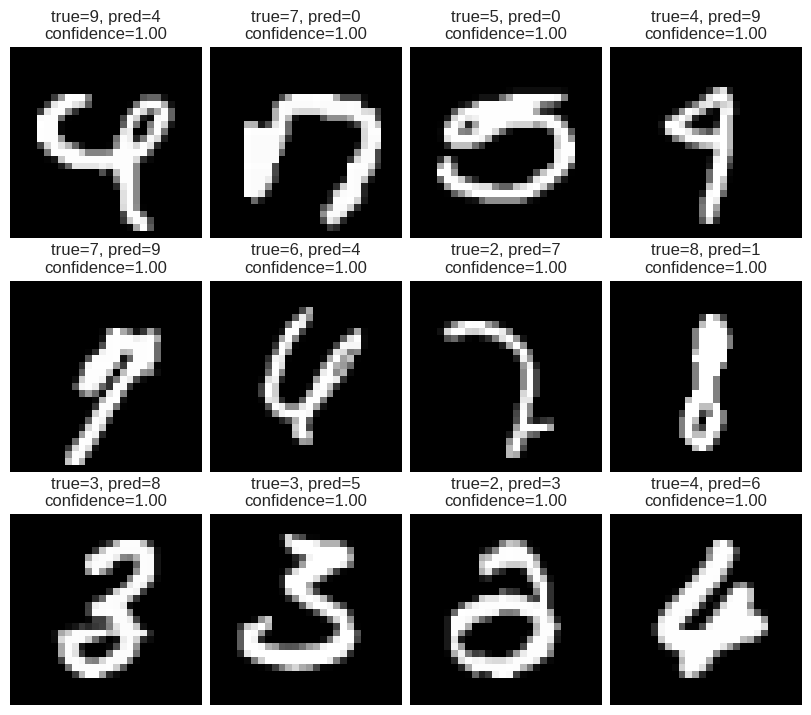

In [28]:
wrong_indices = np.flatnonzero(test_prediction != y_test)
wrong_confidence = test_probability[wrong_indices].max(axis=1)
most_confident_wrong = wrong_indices[np.argsort(wrong_confidence)[-12:][::-1]]

fig, axes = plt.subplots(3, 4, figsize=(8, 7), constrained_layout=True)

for ax, index in zip(axes.ravel(), most_confident_wrong):
    prediction = test_prediction[index]
    confidence = test_probability[index].max()
    ax.imshow(X_test[index].reshape(28, 28), cmap="gray")
    ax.set_title(
        f"true={y_test[index]}, pred={prediction}\n"
        f"confidence={confidence:.2f}"
    )
    ax.axis("off")

plt.show()

In [29]:
def bowl_loss(theta):
    w1, w2 = theta
    return 0.1 * w1**2 + 2.0 * w2**2

def bowl_gradient(theta):
    w1, w2 = theta
    return np.array([0.2 * w1, 4.0 * w2])

def run_sgd(theta0, learning_rate, steps):
    theta = np.array(theta0, dtype=float)
    path = [theta.copy()]
    rows = []

    for step in range(1, steps+1):
        gradient = bowl_gradient(theta)
        update = -learning_rate * gradient
        theta = theta + update # stochastic vanilla grad. descent
        path.append(theta.copy())
        rows.append({
            "step": step,
            "gradient": gradient.copy(),
            "update": update.copy(),
            "theta": theta.copy(),
            "loss": bowl_loss(theta),
        })

    return np.array(path), rows

In [45]:
sgd_path, sgd_rows = run_sgd(theta0=(-4.5, 3.0), learning_rate=0.42, steps=40)
pd.DataFrame(sgd_rows[:2])

,step,gradient,update,theta,loss
0,1,"[-0.9, 12.0]","[0.378, -5.04]","[-4.122, -2.04]",10.022288
1,2,"[-0.8244, -8.16]","[0.346248, 3.4272]","[-3.7757519999999998, 1.3872]",5.274278


In [46]:
sgd_path[-1]

array([-0.1346,  0.    ])

In [47]:
sgd_rows[-1]

{'step': 40,
 'gradient': array([-0.0294, -0.    ]),
 'update': array([0.0123, 0.    ]),
 'theta': array([-0.1346,  0.    ]),
 'loss': np.float64(0.0018116025409453877)}

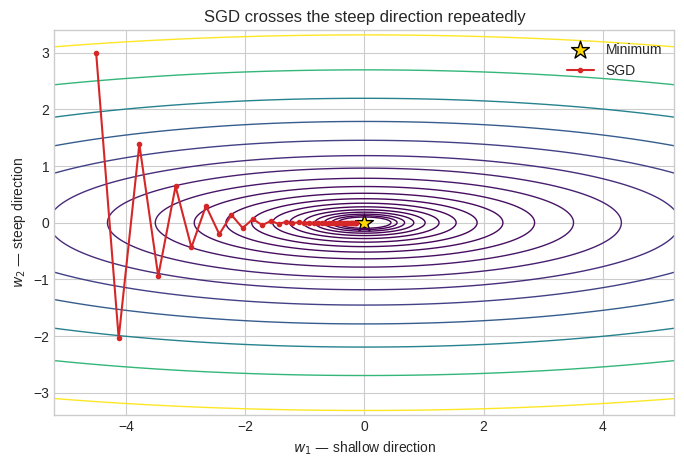

In [48]:
def draw_bowl_contours(ax):
    w1 = np.linspace(-5.2, 5.2, 300)
    w2 = np.linspace(-3.4, 3.4, 300)
    W1, W2 = np.meshgrid(w1, w2)
    Z = 0.1 * W1**2 + 2.0 * W2**2
    levels = np.geomspace(0.02, 22, 18)
    ax.contour(W1, W2, Z, levels=levels, cmap="viridis", linewidths=1)
    ax.scatter(0, 0, marker="*", s=180, color="gold", edgecolor="black", label="Minimum")
    ax.set_xlim(-5.2, 5.2)
    ax.set_ylim(-3.4, 3.4)
    ax.set_xlabel("$w_1$ — shallow direction")
    ax.set_ylabel("$w_2$ — steep direction")


fig, ax = plt.subplots(figsize=(8, 5))
draw_bowl_contours(ax)
ax.plot(sgd_path[:, 0], sgd_path[:, 1], "o-", ms=3, color="#d62728", label="SGD")
ax.set_title("SGD crosses the steep direction repeatedly")
ax.legend()
plt.show()

In [49]:
def run_momentum(theta0, learning_rate, beta, steps):
    theta = np.array(theta0, dtype=float)
    velocity = np.zeros_like(theta)
    path = [theta.copy()]
    rows = []

    for step in range(1, steps+1):
        gradient = bowl_gradient(theta)
        old_velocity = velocity.copy()
        velocity = beta * velocity + gradient
        update = -learning_rate * velocity
        theta = theta + update

        path.append(theta.copy())
        rows.append({
            "step": step,
            "gradient": gradient.copy(),
            "old_velocity": old_velocity,
            "new_velocity": velocity.copy(),
            "update": update.copy(),
            "theta": theta.copy(),
            "loss": bowl_loss(theta),
        })

    return np.array(path), rows



In [58]:
momentum_path, momentum_rows = run_momentum(
    theta0=(-4.5, 3.0),
    learning_rate=0.10,
    beta=0.80,
    steps=40,
)

pd.DataFrame(momentum_rows[:2])

,step,gradient,old_velocity,new_velocity,update,theta,loss
0,1,"[-0.9, 12.0]","[0.0, 0.0]","[-0.9, 12.0]","[0.09000000000000001, -1.2000000000000002]","[-4.41, 1.7999999999999998]",8.42481
1,2,"[-0.8820000000000001, 7.199999999999999]","[-0.9, 12.0]","[-1.6020000000000003, 16.8]","[0.16020000000000004, -1.6800000000000002]","[-4.2498000000000005, 0.11999999999999966]",1.83488


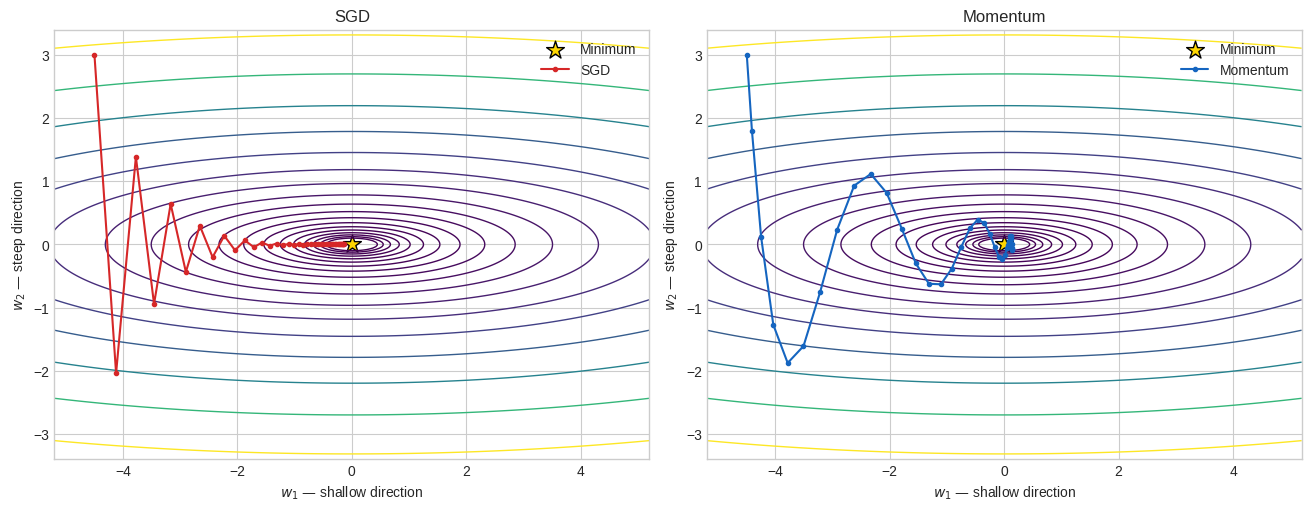

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)

for ax, path, title, color in [
    (axes[0], sgd_path, "SGD", "#d62728"),
    (axes[1], momentum_path, "Momentum", "#1565c0"),
]:
    draw_bowl_contours(ax)
    ax.plot(path[:, 0], path[:, 1], "o-", ms=3, color=color, label=title)
    ax.set_title(title)
    ax.legend()

plt.show()

In [60]:
momentum_rows[-1]

{'step': 40,
 'gradient': array([0.0165, 0.0495]),
 'old_velocity': array([0.088, 0.244]),
 'new_velocity': array([0.0869, 0.2448]),
 'update': array([-0.0087, -0.0245]),
 'theta': array([ 0.0737, -0.0121]),
 'loss': np.float64(0.0008362528741383832)}

In [61]:
def run_adam(
    theta0,
    learning_rate,
    beta1,
    beta2,
    steps,
    epsilon=1e-8,
):
    theta = np.array(theta0, dtype=float)
    first_moment = np.zeros_like(theta)
    second_moment = np.zeros_like(theta)
    path = [theta.copy()]
    rows = []

    for step in range(1, steps + 1):
        gradient = bowl_gradient(theta)
        first_moment = beta1 * first_moment + (1 - beta1) * gradient
        second_moment = beta2 * second_moment + (1 - beta2) * gradient**2

        corrected_first = first_moment / (1 - beta1**step)
        corrected_second = second_moment / (1 - beta2**step)
        update = -learning_rate * corrected_first / (np.sqrt(corrected_second) + epsilon)
        theta = theta + update
        path.append(theta.copy())

        rows.append({
            "step": step,
            "gradient": gradient.copy(),
            "m": first_moment.copy(),
            "v": second_moment.copy(),
            "m_hat": corrected_first.copy(),
            "v_hat": corrected_second.copy(),
            "update": update.copy(),
            "theta": theta.copy(),
            "loss": bowl_loss(theta),
        })

    return np.array(path), rows


adam_path, adam_rows = run_adam(
    theta0=(-4.5, 3.0),
    learning_rate=0.20,
    beta1=0.90,
    beta2=0.999,
    steps=40,
)

pd.DataFrame(adam_rows[:2])

,step,gradient,m,v,m_hat,v_hat,update,theta,loss
0,1,"[-0.9, 12.0]","[-0.08999999999999998, 1.1999999999999997]","[0.0008100000000000008, 0.14400000000000013]","[-0.9, 12.0]","[0.81, 144.0]","[0.1999999977777778, -0.19999999983333336]","[-4.300000002222222, 2.8000000001666665]",17.52900
1,2,"[-0.8600000004444445, 11.200000000666666]","[-0.16700000004444443, 2.200000000066666]","[0.001548790000764446, 0.2692960000149336]","[-0.8789473686549709, 11.57894736877193]","[0.7747823915780224, 134.71535768631176]","[0.19971146158045544, -0.19952187659627119]","[-4.100288540641767, 2.6004781235703955]",15.20621


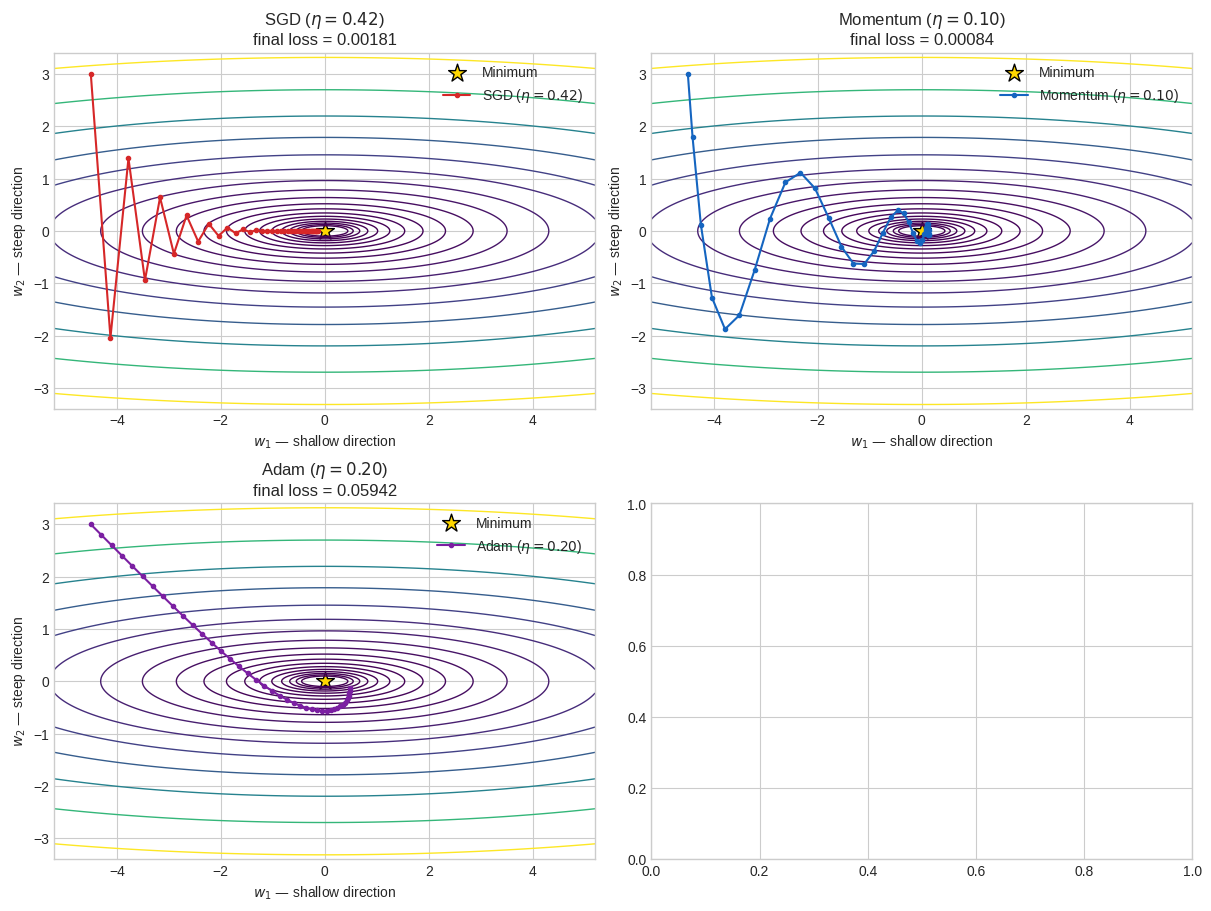

In [62]:
optimizer_paths = {
    "SGD ($\\eta=0.42$)": (sgd_path, "#d62728"),
    "Momentum ($\\eta=0.10$)": (momentum_path, "#1565c0"),
    "Adam ($\\eta=0.20$)": (adam_path, "#7b1fa2"),
}

fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
for ax, (name, (path, color)) in zip(axes.ravel(), optimizer_paths.items()):
    draw_bowl_contours(ax)
    ax.plot(path[:, 0], path[:, 1], "o-", ms=3, color=color, label=name)
    ax.set_title(f"{name}\nfinal loss = {bowl_loss(path[-1]):.5f}")
    ax.legend()

plt.show()